In [6]:
# @title CONFIGURAÇÃO DE AMBIENTE (LOCAL / GOOGLE COLAB)
# ==============================================================================
# CONFIGURAÇÃO DE AMBIENTE (LOCAL / GOOGLE COLAB)
# ==============================================================================
import sys
import os
import subprocess

# 1. Detecção do ambiente (Google Colab vs. Local)
EM_COLAB = "google.colab" in sys.modules

# 2. Instalação automática de dependências ausentes no Google Colab
if EM_COLAB:
    print("Ambiente detectado: Google Colab. Instalando bibliotecas necessárias...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "sktime", "bayesian-optimization", "xgboost>=2.0.0"],
        check=True
    )
    print("Dependências instaladas com sucesso no Google Colab!")
else:
    print("Ambiente detectado: Local.")

# 3. Resolução da raiz do projeto
raiz_projeto = os.path.abspath(os.getcwd())
if raiz_projeto not in sys.path:
    sys.path.insert(0, raiz_projeto)

print(f"Raiz do projeto configurada: {raiz_projeto}")

Ambiente detectado: Local.
Raiz do projeto configurada: /home/pao/Downloads/mestrado_censo_reduzido-master


# XGBoost 2.0+ Ponderado - Censo Demográfico 2000 (Salvador e Validação em Brasília - DF)

[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oscardasilva0/mestrado_censo_reduzido/blob/master/xg_boost2_1.ipynb)

> **Execução no Google Colab:** Clique no badge acima para abrir este notebook diretamente no Colab. Os microdados são importados automaticamente via URLs do GitHub (`popn_2000_salvador.csv` e `popn_2000_brasilia.csv`) e as bibliotecas necessárias (`sktime`, `bayesian-optimization`, `xgboost`) são instaladas automaticamente na Célula 1.

Este notebook implementa o pipeline de **Gradient Boosting (XGBoost)** para estimação da renda domiciliar em salários mínimos (`renda_sal_min_V7617`) no Censo Demográfico 2000.

### Passos Lógicos Preservados:
1. **Carregamento e Filtro Inicial**: Carga dos microdados com tratamento de NAs qualitativos e manutenção dos faltantes numéricos para aprendizado nativo do algoritmo.
2. **Sumário Completo de Valores Ausentes**: Diagnóstico estatístico ordenado por coluna.
3. **Preparação para ML (Divisão Estratificada e DMatrix)**: Partição estratificada em Treino (56%), Validação (24%) e Teste (20%) com pesos amostrais.
4. **Modelo Inicial (Baseline com Perda Pseudo-Huber)**: Ajuste com taxa de aprendizado suave e early stopping via SMAPE ponderado.
5. **Visualização e Diagnóstico do Modelo Baseline**: Ganho dos preditores e validação por decis via `plot_validation`.
6. **Otimização Bayesiana com 5-Fold CV**: Calibração conjunta da família de perdas e hiperparâmetros de regularização.
7. **Treinamento do Modelo Final Otimizado**: Reajuste nos 80% completos da base e avaliação honesta no Teste (20%).
8. **Teste de Generalização Espacial Externa (Brasília - DF)**: Treinamento em Salvador (BA) e teste de generalização externa em Brasília (DF) para avaliação de drift espacial.
9. **Experimento: Treinamento sem o 1º Decil de Renda**: Teste de robustez a ruídos extremos de pobreza comparando Salvador e Brasília.


In [7]:
# @title Tratamento de dados
import sys
import os
import gc
import sqlite3
import numpy as np
import pandas as pd

# ==============================================================================
# ==============================================================================
# 1. FUNÇÃO: dados_censo
# Carrega os microdados para o Censo 2000 a partir da URL do GitHub ou arquivo local
# e executa a padronização.
# ==============================================================================
def dados_censo(
    nome_cidade=None,
    cod_municipio=None,
    estado=None,
    manter_renda_total=False,
    tudo=False,
    ano=2000,
    caminho_banco=None,
):
    """
    Carrega os microdados para o Censo 2000 a partir da URL do GitHub (ou arquivo local caso disponível)
    e executa a padronização.
    - Se a cidade for 'brasilia' (ou estado 'DF'): carrega popn_2000_brasilia.csv
    - Caso contrário (padrão): carrega popn_2000_salvador.csv
    """
    cidade_norm = str(nome_cidade).strip().lower() if nome_cidade else ""
    estado_norm = str(estado).strip().upper() if estado else ""

    if cidade_norm in ["brasilia", "brasília"] or estado_norm in ["DF", "BRASILIA", "BRASÍLIA"]:
        url_dados = "https://raw.githubusercontent.com/oscardasilva0/mestrado_censo_reduzido/refs/heads/master/popn_2000_brasilia.csv"
        arquivo_local = "popn_2000_brasilia.csv"
    else:
        url_dados = "https://raw.githubusercontent.com/oscardasilva0/mestrado_censo_reduzido/refs/heads/master/popn_2000_salvador.csv"
        arquivo_local = "popn_2000_salvador.csv"

    # Seleciona a fonte dos dados (caminho_banco, URL do GitHub ou arquivo local)
    if caminho_banco is not None:
        fonte = caminho_banco
    elif "google.colab" in sys.modules or not os.path.isfile(arquivo_local):
        fonte = url_dados
    else:
        fonte = arquivo_local

    print(f"Carregando microdados de: {fonte}...")

    if str(fonte).endswith(".db"):
        conexao = sqlite3.connect(fonte)
        try:
            dados_brutos = pd.read_sql_query("SELECT * FROM resultado", conexao)
        finally:
            conexao.close()
    else:
        try:
            dados_brutos = pd.read_csv(fonte, low_memory=False)
        except Exception as e:
            if fonte != url_dados:
                print(f"Aviso: falha ao ler '{fonte}' ({e}). Tentando URL do GitHub...")
                dados_brutos = pd.read_csv(url_dados, low_memory=False)
            elif os.path.isfile(arquivo_local):
                print(f"Aviso: falha na URL ({e}). Carregando arquivo local '{arquivo_local}'...")
                dados_brutos = pd.read_csv(arquivo_local, low_memory=False)
            else:
                raise

    # Padroniza nomes de colunas em maiúsculas
    dados_brutos.columns = [str(col).upper() for col in dados_brutos.columns]

    # Limpeza e tipagem dos dados de 2000
    dados_limpos = preparar_dados_censo_2000(
        dados=dados_brutos,
        manter_renda_total=manter_renda_total,
    )
    del dados_brutos
    gc.collect()

    return dados_limpos


# ==============================================================================
# 2. FUNÇÃO: preparar_dados_censo_2000
# Renomeia, recodifica e tipa as variáveis do Censo Demográfico de 2000.
# ==============================================================================
def preparar_dados_censo_2000(
    dados=None,
    manter_renda_total=False,
):
    """
    Realiza toda a limpeza, criação de variáveis, conversão binária (1/0) e
    definição de categorias fixas para os dados do Censo 2000.
    """
    if dados is None:
        raise ValueError("O parâmetro 'dados' (DataFrame bruto) é obrigatório.")

    df = dados.copy()

    # Passo 1: Dicionário de renomeação (código original IBGE -> nome padronizado)
    mapa_renomeacao_2000 = {
        "P001": "peso_amostral_P001",
        "V1007": "tipo_setor_V1007",
        "V1005": "situacao_setor_V1005",
        "V7100": "n_moradores_V7100",
        "V0110": "n_homens_V0110",
        "V0111": "n_mulheres_V0111",
        "V0201": "especie_dom_V0201",
        "V0105": "total_moradores_V0105",
        "V0202": "tipo_dom_V0202",
        "V0203": "n_comodos_V0203",
        "V0204": "n_dormitorios_V0204",
        "V0205": "condicao_dom_V0205",
        "V0206": "condicao_terreno_V0206",
        "V7203": "densidade_comodo_V7203",
        "V7204": "densidade_dormit_V7204",
        "V0207": "agua_origem_V0207",
        "V0208": "agua_canalizacao_V0208",
        "V0209": "n_banheiros_V0209",
        "V0210": "tem_sanitario_V0210",
        "V0211": "esgoto_forma_V0211",
        "V0212": "lixo_destino_V0212",
        "V0213": "tem_iluminacao_V0213",
        "V0214": "tem_radio_V0214",
        "V0215": "tem_geladeira_V0215",
        "V0216": "tem_videocassete_V0216",
        "V0217": "tem_maquina_lavar_V0217",
        "V0218": "tem_microondas_V0218",
        "V0219": "tem_linha_telefonica_V0219",
        "V0220": "tem_computador_V0220",
        "V0221": "n_tvs_V0221",
        "V0222": "n_carros_V0222",
        "V0223": "n_ar_condicionado_V0223",
        "V1111": "tem_identificacao_V1111",
        "V1112": "tem_ilum_publica_V1112",
        "V1113": "tem_pavimentacao_V1113",
        "V1114": "tem_meio_fio_V1114",
        "V1115": "tem_bueiro_V1115",
        "V1116": "tem_rede_agua_V1116",
        "V7616": "renda_total_V7616",
        "V7617": "renda_sal_min_V7617",
        "PESO_AMOSTRAL_P001": "peso_amostral_P001",
        "SITUACAO_SETOR_V1005": "situacao_setor_V1005",
        "TIPO_SETOR_V1007": "tipo_setor_V1007",
        "N_MORADORES_V7100": "n_moradores_V7100",
        "TOTAL_MORADORES_V0105": "total_moradores_V0105",
        "RENDA_TOTAL_V7616": "renda_total_V7616",
        "RENDA_SAL_MIN_V7617": "renda_sal_min_V7617",
    }
    df = df.rename(columns=mapa_renomeacao_2000)

    if "renda_sal_min_V7617" not in df.columns:
        for cand in [
            "V7617",
            "v7617",
            "RENDA_SAL_MIN_V7617",
            "V4622",
            "v4622",
            "RENDA_SAL_MIN",
            "renda_sal_min",
        ]:
            if cand in df.columns:
                df["renda_sal_min_V7617"] = df[cand]
                break

    if "renda_total_V7616" not in df.columns:
        for cand in [
            "V7616",
            "v7616",
            "RENDA_TOTAL_V7616",
            "V4621",
            "v4621",
            "V4614",
            "RENDA_TOTAL",
            "renda_total",
        ]:
            if cand in df.columns:
                df["renda_total_V7616"] = df[cand]
                break

    if "n_moradores_V7100" not in df.columns and "total_moradores_V0105" in df.columns:
        df["n_moradores_V7100"] = df["total_moradores_V0105"]

    # Passo 2: Cálculo do total de componentes da família (V7401 a V7409)
    colunas_familia = [f"V740{i}" for i in range(1, 10)]
    for col in colunas_familia:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        else:
            df[col] = np.nan

    df["V7401"] = np.where(
        df["V7401"].isna() | (df["V7401"] < 1),
        1.0,
        df["V7401"],
    )
    df["familia_n_componentes_V7400"] = df[colunas_familia].fillna(0).sum(axis=1)

    # Passo 3: Conversão explícita das variáveis numéricas
    colunas_numericas_2000 = [
        "peso_amostral_P001",
        "n_moradores_V7100",
        "n_homens_V0110",
        "n_mulheres_V0111",
        "total_moradores_V0105",
        "n_comodos_V0203",
        "n_dormitorios_V0204",
        "n_banheiros_V0209",
        "densidade_comodo_V7203",
        "densidade_dormit_V7204",
        "n_tvs_V0221",
        "n_carros_V0222",
        "n_ar_condicionado_V0223",
        "familia_n_componentes_V7400",
        "renda_total_V7616",
        "renda_sal_min_V7617",
    ]
    for col in colunas_numericas_2000:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Passo 4: Recodificação das variáveis binárias (1 = Sim -> 1, 2 = Não -> 0, outros -> NaN)
    colunas_binarias_2000 = [
        "tem_sanitario_V0210",
        "tem_iluminacao_V0213",
        "tem_radio_V0214",
        "tem_geladeira_V0215",
        "tem_videocassete_V0216",
        "tem_maquina_lavar_V0217",
        "tem_microondas_V0218",
        "tem_linha_telefonica_V0219",
        "tem_computador_V0220",
        "tem_identificacao_V1111",
        "tem_ilum_publica_V1112",
        "tem_pavimentacao_V1113",
        "tem_meio_fio_V1114",
        "tem_bueiro_V1115",
        "tem_rede_agua_V1116",
    ]
    for col in colunas_binarias_2000:
        if col in df.columns:
            valores_num = pd.to_numeric(df[col], errors="coerce")
            df[col] = np.where(
                valores_num == 1,
                1.0,
                np.where(valores_num == 2, 0.0, np.nan),
            )

    # Passo 5: Conversão das variáveis categóricas para pd.Categorical com níveis fixos do IBGE
    niveis_categoricos_2000 = {
        "situacao_setor_V1005": ["1", "2", "3", "4", "5", "6", "7", "8"],
        "tipo_setor_V1007": ["0", "1", "2", "3", "4", "5", "6", "7"],
        "especie_dom_V0201": ["1", "2", "3"],
        "tipo_dom_V0202": ["1", "2", "3"],
        "condicao_dom_V0205": ["1", "2", "3", "4", "5", "6"],
        "condicao_terreno_V0206": ["1", "2"],
        "agua_origem_V0207": ["1", "2", "3", "4", "5", "6"],
        "agua_canalizacao_V0208": ["1", "2", "3"],
        "esgoto_forma_V0211": ["1", "2", "3", "4", "5", "6"],
        "lixo_destino_V0212": ["1", "2", "3", "4", "5", "6", "7"],
    }
    for col, niveis in niveis_categoricos_2000.items():
        if col in df.columns:
            serie_num = pd.to_numeric(df[col], errors="coerce")
            serie_str = serie_num.dropna().astype(np.int64).astype(str)
            df[col] = pd.Categorical(serie_str.reindex(df.index), categories=niveis)
            del serie_num, serie_str

    # Passo 6: Filtra apenas domicílios com a variável alvo válida
    if "renda_sal_min_V7617" in df.columns:
        df = df[df["renda_sal_min_V7617"].notna()].copy()
    else:
        raise KeyError(
            f"Coluna alvo 'renda_sal_min_V7617' não encontrada nos microdados do Censo 2000. "
            f"Colunas disponíveis: {list(df.columns[:30])}"
        )

    # Passo 7: Seleciona as colunas finais na ordem padrão
    colunas_finais_2000 = [
        "peso_amostral_P001",
        "situacao_setor_V1005",
        "tipo_setor_V1007",
        "n_moradores_V7100",
        "n_homens_V0110",
        "n_mulheres_V0111",
        "especie_dom_V0201",
        "total_moradores_V0105",
        "familia_n_componentes_V7400",
        "tipo_dom_V0202",
        "n_comodos_V0203",
        "n_dormitorios_V0204",
        "condicao_dom_V0205",
        "condicao_terreno_V0206",
        "densidade_comodo_V7203",
        "densidade_dormit_V7204",
        "agua_origem_V0207",
        "agua_canalizacao_V0208",
        "n_banheiros_V0209",
        "tem_sanitario_V0210",
        "esgoto_forma_V0211",
        "lixo_destino_V0212",
        "tem_iluminacao_V0213",
        "tem_radio_V0214",
        "tem_geladeira_V0215",
        "tem_videocassete_V0216",
        "tem_maquina_lavar_V0217",
        "tem_microondas_V0218",
        "tem_linha_telefonica_V0219",
        "tem_computador_V0220",
        "n_tvs_V0221",
        "n_carros_V0222",
        "n_ar_condicionado_V0223",
        "tem_identificacao_V1111",
        "tem_ilum_publica_V1112",
        "tem_pavimentacao_V1113",
        "tem_meio_fio_V1114",
        "tem_bueiro_V1115",
        "tem_rede_agua_V1116",
        "renda_total_V7616",
        "renda_sal_min_V7617",
    ]
    colunas_selecionadas = [c for c in colunas_finais_2000 if c in df.columns]
    df = df[colunas_selecionadas]

    if not manter_renda_total and "renda_total_V7616" in df.columns:
        df.drop(columns=["renda_total_V7616"], inplace=True)

    df_final = df.reset_index(drop=True)
    del df
    gc.collect()

    return df_final


# ==============================================================================
# 5. FUNÇÃO: dividir_base
# Realiza a amostragem estratificada em 2 estágios por decis da variável alvo:
# - 1º Estágio: 80% (Treino+Validação) e 20% (Teste)
# - 2º Estágio: 70% dos 80% para Treino (56%) e 30% dos 80% para Validação (24%)
# ==============================================================================
def dividir_base(
    dados=None,
    target_col="renda_sal_min_V7617",
    weight_col="peso_amostral_P001",
    prop=0.80,
    seed=42,
):
    """
    Divide a base de dados de forma estratificada (em 10 faixas/decis da variável alvo)
    em três subconjuntos: treino (56%), validacao (24%) e teste (20%).
    """
    if dados is None:
        raise ValueError("O parâmetro 'dados' (DataFrame) é obrigatório.")

    df = dados.copy().reset_index(drop=True)

    ordem_linhas = df[target_col].rank(method="first", na_option="bottom")
    df[".faixa"] = np.floor((ordem_linhas - 1) * 10 / len(df)).astype(int) + 1

    def _sortear_estratificado(df_entrada, proporcao, semente):
        gerador = np.random.default_rng(semente)
        indices_sorteados = []

        for _, grupo in df_entrada.groupby(".faixa", sort=True):
            n_total_estrato = len(grupo)
            n_sortear = int(round(n_total_estrato * proporcao))
            n_sortear = max(1, min(n_sortear, n_total_estrato))
            escolhidos = gerador.choice(
                grupo.index.to_numpy(),
                size=n_sortear,
                replace=False,
            )
            indices_sorteados.extend(escolhidos)

        mask_sorteados = df_entrada.index.isin(indices_sorteados)
        df_principal = df_entrada.loc[mask_sorteados].reset_index(drop=True)
        df_restante = df_entrada.loc[~mask_sorteados].reset_index(drop=True)
        del mask_sorteados, indices_sorteados
        return df_principal, df_restante

    treino_valid_df, teste_df = _sortear_estratificado(
        df_entrada=df,
        proporcao=prop,
        semente=seed,
    )

    treino_df, valid_df = _sortear_estratificado(
        df_entrada=treino_valid_df,
        proporcao=0.70,
        semente=seed + 1,
    )
    del treino_valid_df

    treino_df.drop(columns=[".faixa"], inplace=True)
    valid_df.drop(columns=[".faixa"], inplace=True)
    teste_df.drop(columns=[".faixa"], inplace=True)

    n_total = len(df)
    peso_total = df[weight_col].sum()
    peso_tr = treino_df[weight_col].sum()
    peso_val = valid_df[weight_col].sum()
    peso_te = teste_df[weight_col].sum()

    print("--- Verificação da Divisão (Linhas vs Pesos) ---")
    print(
        f"Treino:    {len(treino_df)} linhas ({100 * len(treino_df) / n_total:.1f}%) | "
        f"População Estimada (Peso): {peso_tr:,.0f} ({100 * peso_tr / peso_total:.1f}%)"
    )
    print(
        f"Validação: {len(valid_df)} linhas ({100 * len(valid_df) / n_total:.1f}%) | "
        f"População Estimada (Peso): {peso_val:,.0f} ({100 * peso_val / peso_total:.1f}%)"
    )
    print(
        f"Teste:     {len(teste_df)} linhas ({100 * len(teste_df) / n_total:.1f}%) | "
        f"População Estimada (Peso): {peso_te:,.0f} ({100 * peso_te / peso_total:.1f}%)"
    )

    del df
    gc.collect()

    return {
        "treino": treino_df,
        "validacao": valid_df,
        "teste": teste_df,
    }



In [8]:
# @title IMPORTAÇÃO DE BIBLIOTECAS E MÓDULOS DO PROJETO
# ==============================================================================
# IMPORTAÇÃO DE BIBLIOTECAS E MÓDULOS DO PROJETO
# ==============================================================================
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from bayes_opt import BayesianOptimization, acquisition
# Módulos do projeto na raiz
print(f"XGBoost versão: {xgb.__version__}")
print("Bibliotecas e módulos carregados com sucesso!")

XGBoost versão: 3.4.1
Bibliotecas e módulos carregados com sucesso!


In [9]:
# @title Metricas
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sktime.performance_metrics.forecasting import (
    mean_absolute_percentage_error as sktime_mape,
)


# ==========================================================
# FUNÇÃO 1: CÁLCULO DE MÉTRICAS PONDERADAS (Equivalente ao yardstick)
# ==========================================================
def calcular_metricas(
    real=None,     # Vetor com os valores reais/observados da variável alvo
    predito=None,  # Vetor com os valores preditos pelo modelo
    pesos=None,    # Vetor com os pesos amostrais do Censo associados a cada observação
):
    """
    Calcula as métricas globais ponderadas pelo peso amostral do Censo:
      - RMSE  = Raiz do Erro Quadrático Médio Ponderado (scikit-learn)
      - MAE   = Erro Absoluto Médio Ponderado (scikit-learn)
      - R2    = Coeficiente de Determinação Ponderado (scikit-learn)
      - SMAPE = Erro Percentual Absoluto Médio Simétrico Ponderado em % (sktime)
    """
    # 1. Montar o DataFrame unificado e remover linhas com valores ausentes (garantindo vetores 1D)
    real_vec = np.asarray(real).ravel() if real is not None else None
    pred_vec = np.asarray(predito).ravel() if predito is not None else None
    pesos_vec = np.asarray(pesos).ravel() if pesos is not None else None

    df = pd.DataFrame(
        {
            "verdadeiro": pd.to_numeric(real_vec, errors="coerce"),
            "predicao": pd.to_numeric(pred_vec, errors="coerce"),
            "pesos_censo": 1.0
            if pesos_vec is None
            else pd.to_numeric(pesos_vec, errors="coerce"),
        }
    ).dropna()

    if len(df) == 0:
        raise ValueError(
            "Não há registros válidos após a remoção de valores ausentes (NaNs). "
            "Verifique se os dados reais ou preditos contêm apenas NaNs ou se a amostra carregada está vazia."
        )

    y_true = df["verdadeiro"].to_numpy(dtype=float)
    y_pred = df["predicao"].to_numpy(dtype=float)
    w = df["pesos_censo"].to_numpy(dtype=float)

    # 2. Cálculo de cada métrica ponderada usando scikit-learn e sktime:
    # 2.1. RMSE (Erro Quadrático Médio Ponderado)
    rmse_val = root_mean_squared_error(y_true, y_pred, sample_weight=w)

    # 2.2. MAE (Erro Absoluto Médio Ponderado)
    mae_val = mean_absolute_error(y_true, y_pred, sample_weight=w)

    # 2.3. R2 (Coeficiente de Determinação Ponderado)
    r2_val = r2_score(y_true, y_pred, sample_weight=w)

    # 2.4. SMAPE Ponderado (em %, via sktime com symmetric=True)
    smape_val = sktime_mape(y_true, y_pred, symmetric=True, horizon_weight=w) * 100.0

    # 3. Retorna a tabela no formato horizontal (wide) para o relatório
    tabela_limpa = pd.DataFrame(
        {
            "RMSE": [float(rmse_val)],
            "MAE": [float(mae_val)],
            "R2": [float(r2_val)],
            "SMAPE": [float(smape_val)],
        }
    )

    return tabela_limpa


# ==========================================================
# FUNÇÃO 2: MÉTRICA CUSTOMIZADA DE SMAPE PARA O XGBOOST
# ==========================================================
def eval_smape_censo(
    preds=None,  # Vetor com as previsões (valores numéricos) feitas pelo modelo
    dmatrix=None,  # Objeto de dados nativo do modelo (ex: DMatrix do XGBoost)
):
    """
    Função de avaliação customizada para o treinamento e validação cruzada do XGBoost.
    """
    labels = np.asarray(dmatrix.get_label()).ravel()
    weights = dmatrix.get_weight()
    preds = np.maximum(0.0, np.asarray(preds).ravel())

    if weights is None or len(weights) == 0:
        weights = np.ones(len(labels), dtype=float)
    else:
        weights = np.asarray(weights).ravel()

    smape_val = sktime_mape(labels, preds, symmetric=True, horizon_weight=weights) * 100.0

    return "smape_censo", float(smape_val)


# ==========================================================
# FUNÇÃO 3: GERAÇÃO DO RELATÓRIO CONSOLIDADO
# ==========================================================
def gerar_relatorio(
    pred_train=None,  # Valores preditos para a base de treino
    pred_valid=None,  # Valores preditos para a base de validação
    pred_test=None,  # Valores preditos para a base de teste
    y_treino=None,  # Valores reais/alvo da base de treino
    y_valid=None,  # Valores reais/alvo da base de validação
    y_teste=None,  # Valores reais/alvo da base de teste
    w_treino=None,  # Pesos associados à base de treino
    w_valid=None,  # Pesos associados à base de validação
    w_teste=None,  # Pesos associados à base de teste
):
    """
    Calcula as métricas para as bases fornecidas (Treino, Validação e/ou Teste),
    formata a tabela final e imprime o relatório de desempenho no console.
    """
    # Lista para armazenar as métricas calculadas
    resultados = []

    # Verifica e calcula para a base de Treino
    if pred_train is not None and y_treino is not None:
        df_treino = calcular_metricas(y_treino, pred_train, w_treino)
        df_treino["Base"] = "Treino"
        resultados.append(df_treino)

    # Verifica e calcula para a base de Validação
    if pred_valid is not None and y_valid is not None:
        df_valid = calcular_metricas(y_valid, pred_valid, w_valid)
        df_valid["Base"] = "Validação"
        resultados.append(df_valid)

    # Verifica e calcula para a base de Teste
    if pred_test is not None and y_teste is not None:
        df_teste = calcular_metricas(y_teste, pred_test, w_teste)
        df_teste["Base"] = "Teste"
        resultados.append(df_teste)

    # Verifica se pelo menos uma base foi processada
    if len(resultados) == 0:
        print("Nenhum dado válido foi fornecido para gerar o relatório.")
        return None

    # Une os resultados existentes e formata a tabela final
    tabela_final = pd.concat(resultados, ignore_index=True)
    tabela_final = tabela_final[["Base", "RMSE", "MAE", "R2", "SMAPE"]]

    colunas_numericas = ["RMSE", "MAE", "R2", "SMAPE"]
    tabela_final[colunas_numericas] = tabela_final[colunas_numericas].round(4)

    # Imprime o Relatório
    print("\n==========================================================")
    print(" RELATÓRIO DE DESEMPENHO")
    print("==========================================================\n")
    print(tabela_final.to_string(index=False))
    print("\n==========================================================")

    return tabela_final


In [10]:
# @title Visualizador de Grafico
# ==============================================================================
# BIBLIOTECA DE VISUALIZAÇÃO DE GRÁFICOS E DIAGNÓSTICO DO MODELO (PYTHON)
# Equivalente direto ao arquivo: src/r/visualizacao_graficos.R
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sktime.performance_metrics.forecasting import mean_absolute_percentage_error as sktime_mape


# ==============================================================================
# FUNÇÃO: plot_validation
# Gera o relatório completo de validação com métricas globais, tabela
# diagnóstica ponderada por decil e dois gráficos (Dispersão e SMAPE por Decil).
# ==============================================================================
def plot_validation(
    plot_y=None,                     # Vetor numérico com os valores reais da variável alvo
    plot_pred=None,                  # Vetor numérico com os valores preditos pelo modelo
    plot_w=None,                     # Vetor numérico com os pesos amostrais do Censo (opcional)
    mostrar_metricas_globais=True,   # Se False, omite a exibição da TABELA 1 no console
):
    """
    Função de diagnóstico e validação do modelo.
    Calcula métricas globais, diagnósticos por decil populacional e gera os
    gráficos de Aderência Real vs. Predito e Erro SMAPE por Decil.
    """
    if plot_y is None or plot_pred is None:
        raise ValueError("Os parâmetros 'plot_y' (valores reais) e 'plot_pred' (predições) são obrigatórios.")

    # 1. Base unificada (garantindo vetores 1D)
    y_real = np.array(plot_y, dtype=float).ravel()
    y_pred = np.array(plot_pred, dtype=float).ravel()
    pesos = np.ones_like(y_real) if plot_w is None else np.array(plot_w, dtype=float).ravel()

    # Remove valores nulos (NaNs)
    mascara_valida = ~(np.isnan(y_real) | np.isnan(y_pred) | np.isnan(pesos))
    y_real = y_real[mascara_valida]
    y_pred = y_pred[mascara_valida]
    pesos = pesos[mascara_valida]

    df = pd.DataFrame({"Real": y_real, "Predito": y_pred, "Peso_Num": pesos})

    # 2. TABELA 1: Métricas Globais Ponderadas
    metricas_globais = calcular_metricas(real=y_real, predito=y_pred, pesos=pesos)

    if mostrar_metricas_globais:
        print("\n========================================================================================================")
        print("📊 1. MÉTRICAS GLOBAIS DO MODELO:")
        print("========================================================================================================")
        print(metricas_globais.to_string(index=False))
        print("========================================================================================================\n")

    # 3. TABELA 2: Diagnóstico por Decil Ponderado (10% do peso populacional por decil)
    df_sorted = df.sort_values(by=["Real", "Peso_Num"]).reset_index(drop=True)
    peso_total = df_sorted["Peso_Num"].sum()
    peso_acum = (df_sorted["Peso_Num"].cumsum() - 0.5 * df_sorted["Peso_Num"]) / peso_total
    df_sorted["Decil_Num"] = np.clip(np.ceil(peso_acum * 10).astype(int), 1, 10)
    df_sorted["Decil"] = df_sorted["Decil_Num"].apply(lambda d: f"{d}º Decil")

    linhas_decil = []
    for decil_idx in range(1, 11):
        sub = df_sorted[df_sorted["Decil_Num"] == decil_idx]
        if len(sub) == 0:
            continue

        r = sub["Real"].to_numpy()
        p = sub["Predito"].to_numpy()
        w = sub["Peso_Num"].to_numpy()
        soma_w = w.sum()

        media_w = np.sum(r * w) / soma_w
        var_w = np.sum(w * (r - media_w) ** 2) / soma_w
        dp_w = np.sqrt(var_w)
        vies_w = np.sum((p - r) * w) / soma_w

        # Quantil ponderado (mediana)
        ordem = np.argsort(r)
        r_ord = r[ordem]
        w_ord = w[ordem]
        cum_w = np.cumsum(w_ord) / soma_w
        mediana_w = r_ord[np.searchsorted(cum_w, 0.5)]

        # SMAPE ponderado por decil em %
        smape_d = sktime_mape(r, p, symmetric=True, horizon_weight=w) * 100.0

        linhas_decil.append({
            "Decil": f"{decil_idx}º Decil",
            "N": len(sub),
            "Minimo": float(np.min(r)),
            "Mediana": float(mediana_w),
            "Media": float(media_w),
            "Maximo": float(np.max(r)),
            "Desvio_Padrao": float(dp_w),
            "Vies_Medio": float(vies_w),
            "SMAPE": float(smape_d),
        })

    df_decis_final = pd.DataFrame(linhas_decil)

    print("\n========================================================================================================")
    print("📊 2. TABELA DIAGNÓSTICA POR DECIL PONDERADO:")
    print("========================================================================================================")
    colunas_format = ["Minimo", "Mediana", "Media", "Maximo", "Desvio_Padrao", "Vies_Medio", "SMAPE"]
    df_exibicao = df_decis_final.copy()
    df_exibicao[colunas_format] = df_exibicao[colunas_format].round(3)
    print(df_exibicao.to_string(index=False))
    print("========================================================================================================\n")

    # 4. Gráfico 1: Dispersão Integral (Real vs. Predito)
    teto_global = max(df["Real"].max(), df["Predito"].max()) * 1.05
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    ax1.scatter(df["Real"], df["Predito"], alpha=0.20, color="#1f78b4", s=15, edgecolors="none")
    ax1.plot([0, teto_global], [0, teto_global], color="red", linestyle="--", linewidth=1.5, label="Predição Perfeita (y = x)")
    ax1.set_xlim(0, teto_global)
    ax1.set_ylim(0, teto_global)
    ax1.set_title("Aderência Integral: Renda Real vs. Predita", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Renda Real (Salários Mínimos)", fontsize=10, fontweight="bold")
    ax1.set_ylabel("Renda Predita (Salários Mínimos)", fontsize=10, fontweight="bold")
    ax1.legend(loc="upper left")
    ax1.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()

    # 5. Gráfico 2: SMAPE por Decil
    fig2, ax2 = plt.subplots(figsize=(9, 5))
    barras = ax2.bar(df_decis_final["Decil"], df_decis_final["SMAPE"], color="#1b7837", alpha=0.85, width=0.6)
    for barra in barras:
        altura = barra.get_height()
        ax2.annotate(
            f"{altura:.1f}%",
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )
    ax2.set_title("Erro Médio Percentual Absoluto Simétrico (SMAPE) por Decil", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Decil de Renda (1 = Menor Renda, 10 = Maior Renda)", fontsize=10, fontweight="bold")
    ax2.set_ylabel("SMAPE (%)", fontsize=10, fontweight="bold")
    ax2.set_ylim(0, max(df_decis_final["SMAPE"]) * 1.15)
    ax2.grid(axis="y", linestyle=":", alpha=0.6)
    plt.xticks(rotation=25)
    plt.tight_layout()

    import sys
    if "ipykernel" in sys.modules or plt.isinteractive():
        plt.show()
    else:
        plt.close(fig1)
        plt.close(fig2)

    return {
        "metricas": metricas_globais,
        "tabela_decis": df_decis_final,
        "fig_dispersao": fig1,
        "fig_smape": fig2,
    }


## 1. Carregamento e Filtro Inicial

Função `dados_final(cidade=None, estado="BA")`:
- Carrega os microdados censitários via `dados_censo(nome_cidade=cidade, estado=estado, ano=2000, tudo=False)`;
- Preditores categóricos recebem o nível explícito `"Nao_Informado"`;
- Aplica `dropna` somente nas colunas essenciais especificadas: `n_moradores_V7100`, `n_tvs_V0221`, `n_banheiros_V0209`;


In [11]:
def dados_final(cidade=None, estado="BA"):
    dados = dados_censo(nome_cidade=cidade, estado=estado, ano=2000, tudo=False)

    # 2. Tratar NAs nos preditores (antes da divisão)
    colunas_cat = dados.select_dtypes(include=["object", "category"]).columns
    for col in colunas_cat:
        dados[col] = (
            dados[col]
            .astype(str)
            .replace({"nan": "Nao_Informado", "None": "Nao_Informado"})
            .fillna("Nao_Informado")
            .astype("category")
        )

    # Critério estrito: exige as TRÊS colunas simultaneamente (X && Y && Z) para realizar o dropna
    cols_essenciais = ["n_moradores_V7100", "n_tvs_V0221", "n_banheiros_V0209"]
    if (
        "n_moradores_V7100" in dados.columns
        and "n_tvs_V0221" in dados.columns
        and "n_banheiros_V0209" in dados.columns
    ):
        dados = dados.dropna(subset=cols_essenciais, how='any').reset_index(drop=True)

    # Nota: NAs em colunas numéricas são mantidos intactos, pois o algoritmo XGBoost
    # trata valores faltantes de forma nativa e ótima durante as divisões das árvores.
    return dados

## 1.1. Diagnóstico e Sumário de Valores Nulos e NAs

Reproduz com fidelidade as quatro verificações realizadas no script original em R:
1. Total de NAs em toda a base (`sum(is.na(dados_brutos))`);
2. Total de NAs por coluna (`colSums(is.na(dados_brutos))`);
3. Percentual de NAs por coluna (`(colSums(is.na) / nrow) * 100`);
4. Filtro para exibir apenas as colunas que possuem algum valor ausente.

In [12]:
dados_brutos = dados_final(estado="BA")
print(f"Amostra de linhas carregadas: {len(dados_brutos)}")
dados_brutos.head()

# 1. Quantos NAs existem no TOTAL?
total_nas = int(dados_brutos.isna().sum().sum())
print(f"1. Total de NAs na base inteira: {total_nas}")

# 2. Quantos NAs existem em CADA COLUNA?
na_por_coluna = dados_brutos.isna().sum()
print("\n2. Quantidade de NAs por coluna:")
print(na_por_coluna)

# 3. Qual o PERCENTUAL de NAs em cada coluna?
perc_na_por_coluna = (na_por_coluna / len(dados_brutos)) * 100.0
print("\n3. Percentual (%) de NAs em cada coluna:")
print(perc_na_por_coluna.round(2))

# 4. Filtre para ver APENAS as colunas que têm algum NA
colunas_com_na = na_por_coluna[na_por_coluna > 0]
print("\n4. Colunas que possuem algum NA:")
print(colunas_com_na)

# Tabela sumário formatada e ordenada
df_sumario_nulos = pd.DataFrame({
    "Coluna": colunas_com_na.index,
    "Qtd_Nulos": colunas_com_na.values,
    "Percentual_Nulos": perc_na_por_coluna[colunas_com_na.index].values.round(2),
}).sort_values(by="Qtd_Nulos", ascending=False).reset_index(drop=True)

print("\n" + "=" * 60)
print(" TABELA SUMÁRIO: COLUNAS COM DADOS NULOS (CENSO 2000 - Salvador)")
print("=" * 60)
print(df_sumario_nulos.to_string(index=False))
print("=" * 60)

# 5. Remoção declarativa das 5 variáveis com ausência estrutural (regras de salto / skip logic do Manual do IBGE - CD 1.09)
# Nota: esgoto_forma_V0211 (pulada apenas quando V0209 == 0 e V0210 == 2) é mantida, pois 'Nao_Informado' identifica domicílios sem instalação sanitária.
colunas_remover_salto = [
    "tem_sanitario_V0210",     # Salto quando n_banheiros_V0209 >= 1 (CD 1.09, p. 113-114)
    "tem_pavimentacao_V1113",  # Salto em setores rurais / logradouros não urbanizados (CD 1.09, p. 55-68)
    "tem_identificacao_V1111", # Salto em setores rurais / sem face de logradouro (CD 1.09, p. 55-68)
    "tem_ilum_publica_V1112",  # Salto em setores rurais / sem face de logradouro (CD 1.09, p. 55-68)
    "condicao_terreno_V0206",  # Salto quando condicao_dom_V0205 != {1,2} (CD 1.09, p. 111-112)
]
dados_brutos = dados_brutos.drop(columns=[c for c in colunas_remover_salto if c in dados_brutos.columns])
print(f"\nColunas removidas declarativamente ({len(colunas_remover_salto)}): {colunas_remover_salto}")
print(f"Total de colunas restantes em dados_brutos: {dados_brutos.shape[1]} | Total de NAs restantes: {int(dados_brutos.isna().sum().sum())}")

Carregando microdados de: popn_2000_salvador.csv...


<positron-console-cell-12>:266: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
<positron-console-cell-12>:326: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


Amostra de linhas carregadas: 65448
1. Total de NAs na base inteira: 76673

2. Quantidade de NAs por coluna:
peso_amostral_P001                 0
situacao_setor_V1005               0
tipo_setor_V1007                   0
n_moradores_V7100                  0
n_homens_V0110                     0
n_mulheres_V0111                   0
especie_dom_V0201                  0
total_moradores_V0105              0
familia_n_componentes_V7400        0
tipo_dom_V0202                     0
n_comodos_V0203                    0
n_dormitorios_V0204                0
condicao_dom_V0205                 0
condicao_terreno_V0206             0
densidade_comodo_V7203             0
densidade_dormit_V7204             0
agua_origem_V0207                  0
agua_canalizacao_V0208             0
n_banheiros_V0209                  0
tem_sanitario_V0210            61128
esgoto_forma_V0211                 0
lixo_destino_V0212                 0
tem_iluminacao_V0213               0
tem_radio_V0214                    0
tem

## 2. Preparação para Machine Learning (Divisão Estratificada e DMatrix)

Realizamos a partição amostral em dois estágios:
- **80%** para Treinamento e Validação (56% Treino de ajuste e 24% Validação para *early stopping* e sintonia);
- **20%** estritamente intocados para o Teste final de generalização.

In [13]:
# @title Divisão estratificada da base
# 1. Divisão estratificada da base
conjuntos = dividir_base(
    dados=dados_brutos,
    target_col="renda_sal_min_V7617",
    weight_col="peso_amostral_P001",
    prop=0.80,
    seed=42,
)

treino_df = conjuntos["treino"].copy().reset_index(drop=True)
teste_df = conjuntos["teste"].copy().reset_index(drop=True)
valid_df = conjuntos["validacao"].copy().reset_index(drop=True)

# 2. Verificação de decis da variável alvo (0% a 100%)
probs = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

print("--- Base Inteira ---")
print(dados_brutos["renda_sal_min_V7617"].quantile(probs).round(2))

print("\n--- Base Treino ---")
print(treino_df["renda_sal_min_V7617"].quantile(probs).round(2))

print("\n--- Base Validação ---")
print(valid_df["renda_sal_min_V7617"].quantile(probs).round(2))

print("\n--- Base Teste ---")
print(teste_df["renda_sal_min_V7617"].quantile(probs).round(2))

# Otimização de Memória: Elimina dados_brutos e conjuntos após partição
del dados_brutos, conjuntos
gc.collect()

--- Verificação da Divisão (Linhas vs Pesos) ---
Treino:    36648 linhas (56.0%) | População Estimada (Peso): 364,146 (55.9%)
Validação: 15710 linhas (24.0%) | População Estimada (Peso): 156,114 (24.0%)
Teste:     13090 linhas (20.0%) | População Estimada (Peso): 130,748 (20.1%)
--- Base Inteira ---
0.0       0.00
0.1       1.00
0.2       1.32
0.3       2.00
0.4       2.72
0.5       3.64
0.6       4.84
0.7       6.68
0.8      10.46
0.9      19.60
1.0    1990.73
Name: renda_sal_min_V7617, dtype: float64

--- Base Treino ---
0.0       0.00
0.1       1.00
0.2       1.32
0.3       2.00
0.4       2.72
0.5       3.64
0.6       4.84
0.7       6.68
0.8      10.46
0.9      19.60
1.0    1990.73
Name: renda_sal_min_V7617, dtype: float64

--- Base Validação ---
0.0       0.00
0.1       1.00
0.2       1.32
0.3       2.00
0.4       2.72
0.5       3.64
0.6       4.84
0.7       6.67
0.8      10.46
0.9      19.58
1.0    1708.61
Name: renda_sal_min_V7617, dtype: float64

--- Base Teste ---
0.0      0.00

<positron-console-cell-13>:394: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
<positron-console-cell-13>:395: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
<positron-console-cell-13>:396: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


0

In [14]:
# 1. Codificação de variáveis Dummy com alinhamento rigoroso entre as bases
# Mantém os NaNs originais nas colunas contínuas para o XGBoost tratar de forma nativa
# Otimização de Memória: uso estrito de float32 e xgb.DMatrix
def extrair_dummies(df, colunas_referencia=None):
    X = df.drop(columns=["renda_sal_min_V7617", "peso_amostral_P001"])
    X_dumm = pd.get_dummies(X, drop_first=True, dtype=np.float32)
    if colunas_referencia is not None:
        X_dumm = X_dumm.reindex(columns=colunas_referencia, fill_value=0)
    return X_dumm.astype(np.float32)
print(f"Tamanho do Treino: {len(treino_df)}")
train_w = treino_df["peso_amostral_P001"].to_numpy(dtype=np.float32)
train_y = treino_df["renda_sal_min_V7617"].to_numpy(dtype=np.float32)
train_x = extrair_dummies(treino_df)
colunas_modelo = train_x.columns
dtrain = xgb.DMatrix(train_x, label=train_y, weight=train_w)
print(f"Tamanho do Teste: {len(teste_df)}")
test_w = teste_df["peso_amostral_P001"].to_numpy(dtype=np.float32)
test_y = teste_df["renda_sal_min_V7617"].to_numpy(dtype=np.float32)
test_x = extrair_dummies(teste_df, colunas_referencia=colunas_modelo)
dtest = xgb.DMatrix(test_x, label=test_y, weight=test_w)
print(f"Tamanho da Validação: {len(valid_df)}")
valid_w = valid_df["peso_amostral_P001"].to_numpy(dtype=np.float32)
valid_y = valid_df["renda_sal_min_V7617"].to_numpy(dtype=np.float32)
valid_x = extrair_dummies(valid_df, colunas_referencia=colunas_modelo)
dvalid = xgb.DMatrix(valid_x, label=valid_y, weight=valid_w)
# Otimização de Memória: Liberação dos DataFrames intermediários e matrizes de teste
del treino_df, teste_df, valid_df, test_x
gc.collect()
print(f"\nDMatrix criadas: Treino {train_x.shape} | Validação {valid_x.shape} | Teste ({len(test_y)}, {len(colunas_modelo)})")


Tamanho do Treino: 36648
Tamanho do Teste: 13090
Tamanho da Validação: 15710

DMatrix criadas: Treino (36648, 55) | Validação (15710, 55) | Teste (13090, 55)


## 3. Modelo XGBoost Inicial (Baseline com Perda Pseudo-Huber)

Treinamento do modelo com os parâmetros de referência do arquivo R:
- `objective = "reg:pseudohubererror"` (perda suave e robusta a caudas longas);
- `learning_rate (eta) = 0.01`, `max_depth = 6`;
- `alpha = 1`, `lambda = 1`, `subsample = 0.5`, `colsample_bytree = 1.0`, `huber_slope = 1.0`;
- Monitoramento com `custom_metric = eval_smape_censo` e parada antecipada (`early_stopping_rounds = 50`) na base de validação.

In [15]:
params_base = {
    "objective": "reg:pseudohubererror",
    "learning_rate": 0.01,
    "max_depth": 6,
    "alpha": 1.0,
    "lambda": 1.0,
    "subsample": 0.5,
    "colsample_bytree": 1.0,
    "huber_slope": 1.0,
    "tree_method": "hist",
    "nthread": 4,
    "random_state": 42,
}

print("Treinando modelo XGBoost inicial (Baseline)...")
modelo_xgb = xgb.train(
    params=params_base,
    dtrain=dtrain,
    num_boost_round=1500,
    evals=[(dtrain, "train"), (dvalid, "val")],
    custom_metric=eval_smape_censo,
    early_stopping_rounds=50,
    verbose_eval=100,
    maximize=False,
)

# Salvar o modelo baseline em formato UBJ
print(f"Melhor iteração de parada precoce: {modelo_xgb.best_iteration}")

Treinando modelo XGBoost inicial (Baseline)...
[0]	train-mphe:5.97573	train-smape_censo:85.97469	val-mphe:5.99554	val-smape_censo:85.69143
[100]	train-mphe:3.61968	train-smape_censo:59.37763	val-mphe:3.76741	val-smape_censo:59.94114
[200]	train-mphe:3.41480	train-smape_censo:56.92485	val-mphe:3.63808	val-smape_censo:57.84741
[300]	train-mphe:3.34558	train-smape_censo:56.45441	val-mphe:3.62200	val-smape_censo:57.64518
[344]	train-mphe:3.32724	train-smape_censo:56.38105	val-mphe:3.62209	val-smape_censo:57.68042
Melhor iteração de parada precoce: 294


## 4. Predições e Relatório Consolidado do Modelo Inicial

As previsões são truncadas em zero (`np.maximum(0, preds)`), respeitando o domínio estritamente não negativo da renda domiciliar.

In [16]:
# Predições nas 3 bases (truncadas em zero)
pred_train = np.maximum(0.0, modelo_xgb.predict(dtrain)).ravel()
pred_valid = np.maximum(0.0, modelo_xgb.predict(dvalid)).ravel()
pred_test = np.maximum(0.0, modelo_xgb.predict(dtest)).ravel()

# Relatório consolidado com métricas ponderadas (RMSE, MAE, R2 e SMAPE)
tabela_xgb_base = gerar_relatorio(
    pred_train=pred_train,
    pred_valid=pred_valid,
    pred_test=pred_test,
    y_treino=train_y,
    y_valid=valid_y,
    y_teste=test_y,
    w_treino=train_w,
    w_valid=valid_w,
    w_teste=test_w,
)

print("\n" + "=" * 58)
print(" RELATÓRIO DE DESEMPENHO - XGBOOST BASELINE (Salvador 2000)")
print("=" * 58)
print(tabela_xgb_base)
print("=" * 58)

# Salvar métricas do modelo baseline


 RELATÓRIO DE DESEMPENHO

     Base    RMSE    MAE     R2   SMAPE
   Treino 15.1259 3.9724 0.3629 56.3811
Validação 19.0903 4.2748 0.2477 57.6804
    Teste 13.0994 4.2582 0.3957 58.1543


 RELATÓRIO DE DESEMPENHO - XGBOOST BASELINE (Salvador 2000)
        Base     RMSE     MAE      R2    SMAPE
0     Treino  15.1259  3.9724  0.3629  56.3811
1  Validação  19.0903  4.2748  0.2477  57.6804
2      Teste  13.0994  4.2582  0.3957  58.1543


## 5. Visualização e Diagnóstico do Modelo Baseline

Exibição da importância dos preditores por ganho (*Gain*) e avaliação estratificada por decis de renda via `plot_validation`.

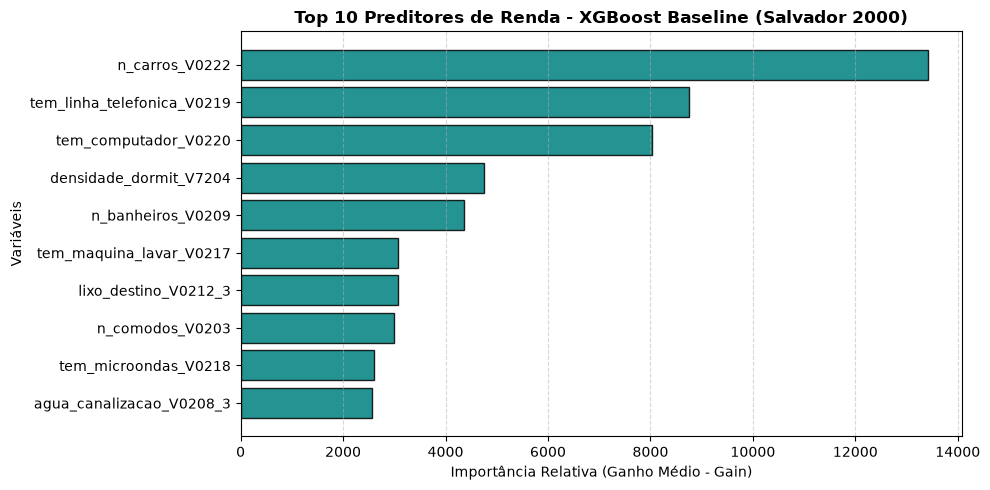


📊 2. TABELA DIAGNÓSTICA POR DECIL PONDERADO:
    Decil    N  Minimo  Mediana  Media  Maximo  Desvio_Padrao  Vies_Medio   SMAPE
 1º Decil 1321    0.00     0.00  0.303    1.00          0.375       2.194 153.276
 2º Decil 1288    1.00     1.00  1.100    1.32          0.133       1.328  70.109
 3º Decil 1339    1.32     1.73  1.740    2.00          0.220       1.133  47.730
 4º Decil 1312    2.00     2.36  2.380    2.72          0.228       0.939  37.810
 5º Decil 1324    2.72     3.18  3.186    3.65          0.248       0.466  36.550
 6º Decil 1303    3.65     4.17  4.221    4.91          0.347       0.041  36.545
 7º Decil 1309    4.91     5.77  5.791    6.79          0.567      -0.113  43.014
 8º Decil 1317    6.79     8.34  8.489   10.60          1.098      -0.770  48.334
 9º Decil 1292   10.60    13.74 14.304   19.87          2.630      -2.260  49.872
10º Decil 1285   19.87    31.46 42.161  662.25         37.480     -16.831  58.294



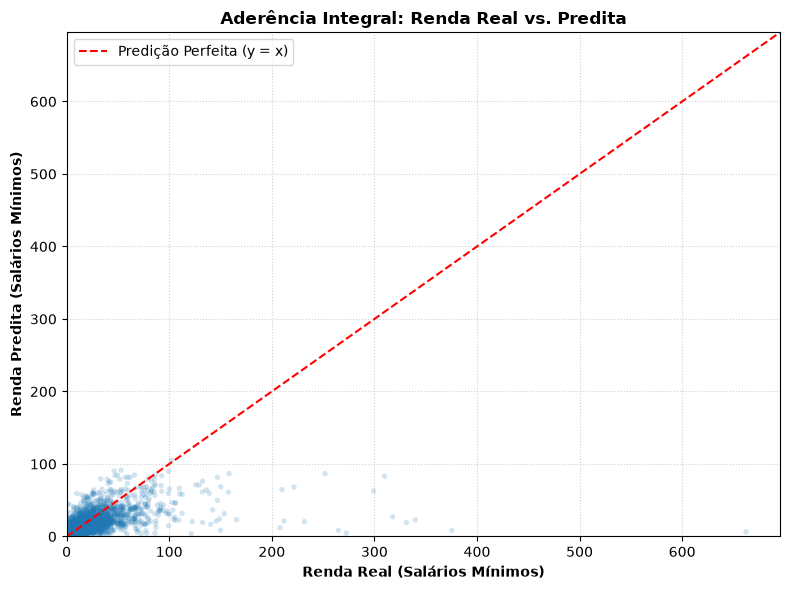

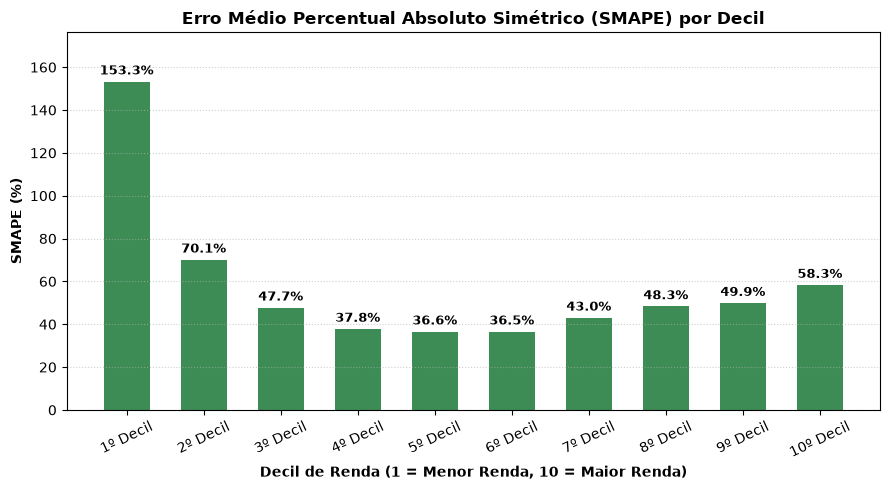

11763

In [17]:
# 1. Importância das Variáveis (Ganho Médio das Árvores)
score_importancia = modelo_xgb.get_score(importance_type="gain")
df_imp = pd.DataFrame({
    "Variavel": list(score_importancia.keys()),
    "Ganho": list(score_importancia.values()),
}).sort_values(by="Ganho", ascending=False).reset_index(drop=True)

top10 = df_imp.head(10).sort_values(by="Ganho", ascending=True)

# Gráfico de barras horizontais
plt.figure(figsize=(10, 5))
plt.barh(top10["Variavel"], top10["Ganho"], color="teal", edgecolor="black", alpha=0.85)
plt.title("Top 10 Preditores de Renda - XGBoost Baseline (Salvador 2000)", fontsize=12, fontweight="bold")
plt.xlabel("Importância Relativa (Ganho Médio - Gain)", fontsize=10)
plt.ylabel("Variáveis", fontsize=10)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Diagnóstico Padronizado por Decis de Renda (via plot_validation)
plot_validation(
    plot_y=test_y,
    plot_pred=pred_test,
    plot_w=test_w,
    mostrar_metricas_globais=False,
)

# Otimização de Memória: Fechar buffers de figuras e coletar lixo
plt.close("all")
gc.collect()

## 6. Otimização Bayesiana com 5-Fold Cross-Validation Estratificado

Unimos **Treino (56%)** e **Validação (24%)** totalizando **80% dos dados** (`dtrain_val`). O conjunto de **Teste (20%)** permanece isolado.

A função objetivo bayesiana calibra conjuntamente:
1. **Família da Função de Perda** (`obj_idx`):
   - `1`: `reg:tweedie` (combinação Gamma-Poisson);
   - `2`: `reg:squarederror` (L2);
   - `3`: `reg:absoluteerror` (L1 robusto);
   - `4`: `reg:pseudohubererror` (híbrido suave L2/L1);
2. **Taxa de Aprendizado** (`eta`): 0.005 a 0.05;
3. **Profundidade Máxima** (`max_depth`): 4 a 16;
4. **Amostragens e Regularizações**: `subsample`, `colsample_bytree`, `alpha`, `lambda`, `huber_slope`.

In [18]:
# 1. União Treino + Validação (80%) para Cross-Validation com QuantileDMatrix
train_val_x = pd.concat([train_x, valid_x], ignore_index=True)
train_val_y = np.concatenate([train_y, valid_y]).astype(np.float32)
train_val_w = np.concatenate([train_w, valid_w]).astype(np.float32)
# NOTA: xgb.cv exige xgb.DMatrix padrão para suportar o fatiamento de folds cruzados
dtrain_val = xgb.DMatrix(train_val_x, label=train_val_y, weight=train_val_w)
# Otimização de Memória: Elimina partições separadas de treino e validação
del train_x, valid_x
gc.collect()
# 2. Criação dos 5 Folds Estratificados por Decis de Renda
np.random.seed(42)
ordem = pd.Series(train_val_y).rank(method="first").to_numpy()
faixas_decis = np.floor((ordem - 1) * 10 / len(train_val_y)).astype(int)
folds_indices = [[] for _ in range(5)]
for dec in range(10):
    idx_dec = np.where(faixas_decis == dec)[0]
    sorteados = np.random.permutation(idx_dec)
    divisoes = np.array_split(sorteados, 5)
    for k in range(5):
        folds_indices[k].extend(divisoes[k])
folds_cv = []
todos_indices = np.arange(len(train_val_y))
for k in range(5):
    val_idx = np.array(folds_indices[k])
    tr_idx = np.setdiff1d(todos_indices, val_idx)
    folds_cv.append((tr_idx, val_idx))
# 3. Função Objetivo Bayesiana
lista_objetivos = [
    "reg:tweedie",
    "reg:squarederror",
    "reg:absoluteerror",
    "reg:pseudohubererror",
]
historico_iteracoes = []
def xgb_cv_smape(obj_idx, eta, max_depth, subsample, colsample_bytree, alpha, lambda_reg, huber_slope):
    idx_int = int(round(obj_idx)) - 1
    idx_int = max(0, min(3, idx_int))
    obj_escolhido = lista_objetivos[idx_int]

    params = {
        "objective": obj_escolhido,
        "learning_rate": float(eta),
        "max_depth": int(round(max_depth)),
        "subsample": float(subsample),
        "colsample_bytree": float(colsample_bytree),
        "alpha": float(alpha),
        "lambda": float(lambda_reg),
        "tree_method": "hist",
        "nthread": 4,
        "random_state": 42,
    }

    if obj_escolhido == "reg:pseudohubererror":
        params["huber_slope"] = float(huber_slope)
    elif obj_escolhido == "reg:tweedie":
        params["tweedie_variance_power"] = 1.5

    try:
        cv_res = xgb.cv(
            params=params,
            dtrain=dtrain_val,
            folds=folds_cv,
            num_boost_round=1500,
            custom_metric=eval_smape_censo,
            early_stopping_rounds=30,
            maximize=False,
            verbose_eval=False,
        )

        coluna_smape = [c for c in cv_res.columns if "test" in c and "mean" in c and "smape" in c]
        coluna_smape = coluna_smape[0] if len(coluna_smape) > 0 else "test-smape_censo-mean"
        menor_smape = float(cv_res[coluna_smape].min())
        best_iter = int(cv_res[coluna_smape].idxmin() + 1)

        historico_iteracoes.append({"smape": menor_smape, "nrounds": best_iter, "obj": obj_escolhido})
        del cv_res
        gc.collect()
        return -menor_smape
    except Exception as e:
        print(f"Falha no CV: {e}")
        gc.collect()
        return -999.0
# 4. Espaço de Busca
bounds = {
    "obj_idx": (1.0, 4.0),
    "eta": (0.005, 0.05),
    "max_depth": (4.0, 16.0),
    "subsample": (0.40, 0.80),
    "colsample_bytree": (0.60, 1.00),
    "alpha": (0.0, 5.0),
    "lambda_reg": (0.0, 5.0),
    "huber_slope": (0.2, 5.0),
}
# 5. Execução do Otimizador Bayesiano
print("Iniciando Otimização Bayesiana com 5-Fold CV...")
opt_bayes = BayesianOptimization(
    f=xgb_cv_smape,
    pbounds=bounds,
    acquisition_function=acquisition.UpperConfidenceBound(kappa=2.576),
    random_state=42,
    verbose=2,
)
opt_bayes.maximize(init_points=8, n_iter=20)
# 6. Extração dos Melhores Hiperparâmetros
melhor_p = opt_bayes.max["params"]
melhor_smape = -opt_bayes.max["target"]
idx_obj_opt = int(round(melhor_p["obj_idx"])) - 1
idx_obj_opt = max(0, min(3, idx_obj_opt))
obj_opt = lista_objetivos[idx_obj_opt]
melhor_hist = min(historico_iteracoes, key=lambda x: x["smape"])
nrounds_opt = melhor_hist["nrounds"]
print("\n" + "=" * 58)
print(f"🏆 MELHOR SMAPE (CV 5-FOLDS): {melhor_smape:.4f}%")
print(f"Objetivo Selecionado:       {obj_opt}")
print(f"Nrounds Ótimo:              {nrounds_opt}")
print("=" * 58)
gc.collect()

Iniciando Otimização Bayesiana com 5-Fold CV...
|   iter    |  target   |  obj_idx  |    eta    | max_depth | subsample | colsam... |   alpha   | lambda... | huber_... |
-------------------------------------------------------------------------------------------------------------------------
| 1         | -59.70658 | 2.1236203 | 0.0477821 | 12.783927 | 0.6394633 | 0.6624074 | 0.7799726 | 0.2904180 | 4.3576454 |
| 2         | -57.26899 | 2.8033450 | 0.0368632 | 4.2470139 | 0.7879639 | 0.9329770 | 1.0616955 | 0.9091248 | 1.0803416 |
| 3         | -58.64460 | 1.9127267 | 0.0286140 | 9.1833402 | 0.5164916 | 0.8447411 | 0.6974693 | 1.4607232 | 1.9585368 |
| 4         | -58.54619 | 2.3682099 | 0.0403329 | 6.3960853 | 0.6056937 | 0.8369658 | 0.2322520 | 3.0377242 | 1.0185157 |
| 5         | -58.69087 | 1.1951547 | 0.0476998 | 15.587584 | 0.7233589 | 0.7218455 | 0.4883605 | 3.4211651 | 2.3127319 |
| 6         | -57.79583 | 1.3661147 | 0.0272829 | 4.4126622 | 0.7637281 | 0.7035119 | 3.3126114 | 

0

## 7. Treinamento do Modelo Final Otimizado (80% da Base)

Ajustamos o modelo final utilizando os **80% completos** da base (`dtrain_val`) com os hiperparâmetros ótimos e avaliamos sua acurácia nos **20% de Teste** independentes.

Parâmetros finais para treino nos 80% completos:
  objective           : reg:pseudohubererror
  learning_rate       : 0.005
  max_depth           : 9
  subsample           : 0.8
  colsample_bytree    : 0.6
  alpha               : 5.0
  lambda              : 3.990589195331747
  tree_method         : hist
  nthread             : 4
  random_state        : 42
  huber_slope         : 2.2800756477961897
[0]	train_val-mphe:12.30753	train_val-smape_censo:86.13996
[100]	train_val-mphe:8.11654	train_val-smape_censo:66.18550
[200]	train_val-mphe:7.08586	train_val-smape_censo:59.49568
[300]	train_val-mphe:6.62735	train_val-smape_censo:56.33054
[400]	train_val-mphe:6.39846	train_val-smape_censo:54.77857
[500]	train_val-mphe:6.25809	train_val-smape_censo:53.98360
[600]	train_val-mphe:6.16708	train_val-smape_censo:53.54527
[700]	train_val-mphe:6.10055	train_val-smape_censo:53.26537
[764]	train_val-mphe:6.06372	train_val-smape_censo:53.13598

 RELATÓRIO DE DESEMPENHO

  Base    RMSE    MAE     R2   SM

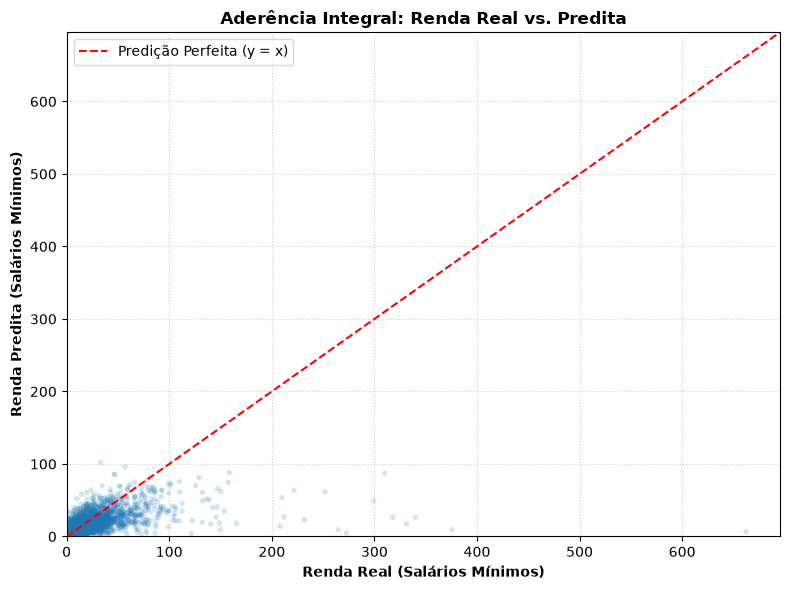

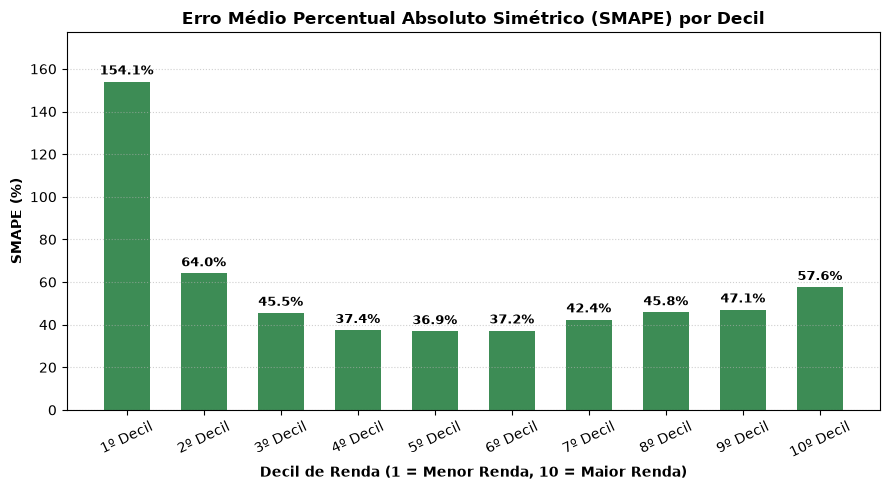

7821

In [19]:
# 1. Parâmetros finais alinhados com a melhor configuração
params_final = {
    "objective": obj_opt,
    "learning_rate": float(melhor_p["eta"]),
    "max_depth": int(round(melhor_p["max_depth"])),
    "subsample": float(melhor_p["subsample"]),
    "colsample_bytree": float(melhor_p["colsample_bytree"]),
    "alpha": float(melhor_p["alpha"]),
    "lambda": float(melhor_p["lambda_reg"]),
    "tree_method": "hist",
    "nthread": 4,
    "random_state": 42,
}

if obj_opt == "reg:pseudohubererror":
    params_final["huber_slope"] = float(melhor_p["huber_slope"])
elif obj_opt == "reg:tweedie":
    params_final["tweedie_variance_power"] = 1.5

print("Parâmetros finais para treino nos 80% completos:")
for k, v in params_final.items():
    print(f"  {k:20s}: {v}")

# 2. Treinamento Final em dtrain_val (80% completos)
modelo_xgb_opt = xgb.train(
    params=params_final,
    dtrain=dtrain_val,
    num_boost_round=nrounds_opt,
    evals=[(dtrain_val, "train_val")],
    custom_metric=eval_smape_censo,
    verbose_eval=100,
    maximize=False,
)

# Salvar o modelo final otimizado

# 3. Predições truncadas em zero
pred_train_opt = np.maximum(0.0, modelo_xgb_opt.predict(dtrain_val)).ravel()
pred_test_opt = np.maximum(0.0, modelo_xgb_opt.predict(dtest)).ravel()

# 4. Relatório consolidado final
tabela_xgb_opt = gerar_relatorio(
    pred_train=pred_train_opt,
    pred_test=pred_test_opt,
    y_treino=train_val_y,
    y_teste=test_y,
    w_treino=train_val_w,
    w_teste=test_w,
)

print("\n" + "=" * 58)
print(" RELATÓRIO DE DESEMPENHO - MODELO FINAL OTIMIZADO (Salvador 2000)")
print("=" * 58)
print(tabela_xgb_opt)
print("=" * 58)

# 5. Exportação da Tabela e Diagnóstico Padronizado

plot_validation(
    plot_y=test_y,
    plot_pred=pred_test_opt,
    plot_w=test_w,
    mostrar_metricas_globais=False,
)

# Otimização de Memória: Fechar figuras e liberar modelo baseline obsoleto
plt.close("all")
if "modelo_xgb" in locals():
    del modelo_xgb
gc.collect()

## 8. Teste de Generalização Espacial Externa (Brasília - DF)

Carregamos a base de Brasília (DF - Censo 2000) utilizando a função `dados_final(cidade="brasilia", estado="DF")`, preservando o mesmo tratamento de NAs e alinhamento rigoroso de colunas.
Neste teste avaliamos a capacidade de generalização espacial externa do modelo treinado com dados de Salvador (BA) ao ser avaliado diretamente sobre o Distrito Federal (Brasília - DF).


Carregando microdados de: popn_2000_brasilia.csv...


<positron-console-cell-20>:266: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
<positron-console-cell-20>:326: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


📊 Total de domicílios em Brasília (DF): 53887
Colunas Treino Salvador: 55 | Colunas Brasília: 55

 RELATÓRIO DE DESEMPENHO

 Base    RMSE    MAE    R2   SMAPE
Teste 28.9225 7.4844 0.217 54.4214


 RELATÓRIO DE DESEMPENHO NO TESTE EXTERNO (BRASÍLIA - DF)
 Treino do modelo em Salvador (BA) e teste em Brasília (DF)
                            Base     RMSE     MAE     R2    SMAPE
0  Teste Externo (Brasília - DF)  28.9225  7.4844  0.217  54.4214

 COMPARATIVO DE GENERALIZAÇÃO ESPACIAL: SALVADOR (BA) vs. BRASÍLIA (DF)
                                   Cenário    RMSE    MAE     R2   SMAPE
Treino Salvador / Teste Salvador (Interno) 13.1354 4.2285 0.3924 56.7913
Treino Salvador / Teste Brasília (Externo) 28.9225 7.4844 0.2170 54.4214

📊 2. TABELA DIAGNÓSTICA POR DECIL PONDERADO:
    Decil    N  Minimo  Mediana  Media  Maximo  Desvio_Padrao  Vies_Medio   SMAPE
 1º Decil 5495    0.00     1.00  0.745    1.42          0.508       2.158 110.115
 2º Decil 5465    1.42     1.99  1.924    2.32      

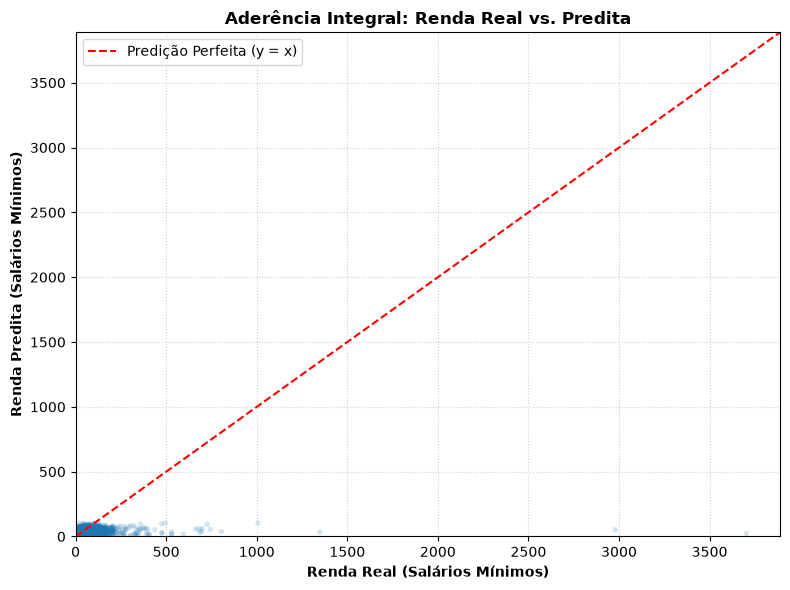

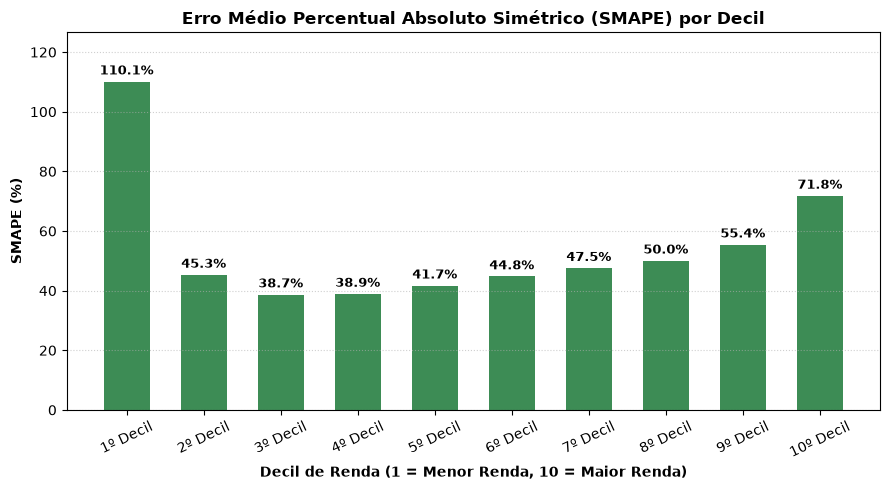

7891

In [20]:
# 1. Liberação preventiva de memória antes de alocar a base de Brasília (DF)
if "dtrain_val" in locals():
    del dtrain_val
gc.collect()
# Carregamento da base de Brasília (DF)
bsb_df = dados_final(cidade="brasilia", estado="DF")
print(f"📊 Total de domicílios em Brasília (DF): {len(bsb_df)}")
# 2. Renda Real e Pesos Amostrais de Brasília em float32
y_bsb = bsb_df["renda_sal_min_V7617"].to_numpy(dtype=np.float32)
w_bsb = bsb_df["peso_amostral_P001"].to_numpy(dtype=np.float32)
# 3. Dummies com alinhamento rigoroso às colunas de treino de Salvador em float32
x_bsb = extrair_dummies(bsb_df, colunas_referencia=colunas_modelo)
print(f"Colunas Treino Salvador: {len(colunas_modelo)} | Colunas Brasília: {x_bsb.shape[1]}")
# 4. Construção da DMatrix de Brasília com pesos amostrais
dbsb = xgb.DMatrix(x_bsb, label=y_bsb, weight=w_bsb)
# Otimização de Memória: Liberação imediata de bsb_df e x_bsb
del bsb_df, x_bsb
gc.collect()
# 5. Predições truncadas em zero
pred_bsb = np.maximum(0.0, modelo_xgb_opt.predict(dbsb)).ravel()
# 6. Relatório de Desempenho no Teste Externo (Brasília)
tabela_xgb_bsb = gerar_relatorio(
    pred_test=pred_bsb,
    y_teste=y_bsb,
    w_teste=w_bsb,
)
tabela_xgb_bsb["Base"] = "Teste Externo (Brasília - DF)"
print("\n" + "=" * 58)
print(" RELATÓRIO DE DESEMPENHO NO TESTE EXTERNO (BRASÍLIA - DF)")
print(" Treino do modelo em Salvador (BA) e teste em Brasília (DF)")
print("=" * 58)
print(tabela_xgb_bsb)
print("=" * 58)
# 7. Comparativo de Generalização Espacial: Salvador (Interno) vs. Brasília (Externo)
rmse_salvador = tabela_xgb_opt.loc[tabela_xgb_opt["Base"] == "Teste", "RMSE"].values[0] if "tabela_xgb_opt" in locals() and "Teste" in tabela_xgb_opt["Base"].values else np.nan
mae_salvador = tabela_xgb_opt.loc[tabela_xgb_opt["Base"] == "Teste", "MAE"].values[0] if "tabela_xgb_opt" in locals() and "Teste" in tabela_xgb_opt["Base"].values else np.nan
r2_salvador = tabela_xgb_opt.loc[tabela_xgb_opt["Base"] == "Teste", "R2"].values[0] if "tabela_xgb_opt" in locals() and "Teste" in tabela_xgb_opt["Base"].values else np.nan
smape_salvador = tabela_xgb_opt.loc[tabela_xgb_opt["Base"] == "Teste", "SMAPE"].values[0] if "tabela_xgb_opt" in locals() and "Teste" in tabela_xgb_opt["Base"].values else np.nan
tabela_comp_espacial = pd.DataFrame([
    {
        "Cenário": "Treino Salvador / Teste Salvador (Interno)",
        "RMSE": rmse_salvador,
        "MAE": mae_salvador,
        "R2": r2_salvador,
        "SMAPE": smape_salvador,
    },
    {
        "Cenário": "Treino Salvador / Teste Brasília (Externo)",
        "RMSE": float(tabela_xgb_bsb.loc[0, "RMSE"]),
        "MAE": float(tabela_xgb_bsb.loc[0, "MAE"]),
        "R2": float(tabela_xgb_bsb.loc[0, "R2"]),
        "SMAPE": float(tabela_xgb_bsb.loc[0, "SMAPE"]),
    }
])
print("\n" + "=" * 78)
print(" COMPARATIVO DE GENERALIZAÇÃO ESPACIAL: SALVADOR (BA) vs. BRASÍLIA (DF)")
print("=" * 78)
print(tabela_comp_espacial.to_string(index=False))
print("=" * 78)
# 8. Exportação e Diagnóstico Espacial Padronizado
plot_validation(
    plot_y=y_bsb,
    plot_pred=pred_bsb,
    plot_w=w_bsb,
    mostrar_metricas_globais=False,
)
plt.close("all")
gc.collect()


## 9. Experimento: Treinamento sem o 1º Decil de Renda

Neste experimento, **removemos todo o primeiro decil de renda durante o treinamento** na base de Salvador.

### Motivação:
Conforme observado nos diagnósticos e gráficos anteriores, a predição dos domicílios do 1º decil foi muito difícil de ser realizada pelo modelo, apresentando grande dispersão e erros elevados. Acredita-se que essa faixa inicial concentre muito ruído (rendas nulas, valores próximos de zero e subdeclarações) que atrapalha o aprendizado do algoritmo. A hipótese é que, ao remover todo o 1º decil no treinamento, o modelo poderá aprender melhor sem todo esse ruído.

### Procedimento:
1. **Treino e Validação (Salvador)**: Treina o modelo com a base de Salvador removendo todo o primeiro decil ($y \le Q_{0.10}$);
2. **Teste Salvador**: Avalia o modelo resultante na base de teste de Salvador completa (com todos os decis, incluindo o 1º decil);
3. **Teste Brasília (DF)**: Testa o modelo na base de Brasília **sem remover o primeiro decil** (base 100% íntegra);
4. **Métricas e Gráficos**: Apresenta as tabelas de métricas comparativas para Salvador e Brasília e os gráficos de validação (`plot_validation`).


Valor de corte do 1º Decil (Percentil 10%) em Salvador: 1.0000 SM
Total de domicílios Treino+Validação (Original):  52358
Total de domicílios Treino+Validação (Sem 1º Decil): 44120 (Removidos: 8238)

Treinando modelo XGBoost com a base de Salvador SEM o 1º Decil...
[0]	train_sem_d1-mphe:16.58536	train_sem_d1-smape_censo:87.87511
[100]	train_sem_d1-mphe:9.32452	train_sem_d1-smape_censo:58.13666
[200]	train_sem_d1-mphe:7.96146	train_sem_d1-smape_censo:49.05663
[300]	train_sem_d1-mphe:7.41467	train_sem_d1-smape_censo:44.89922
[400]	train_sem_d1-mphe:7.14565	train_sem_d1-smape_censo:42.81048
[500]	train_sem_d1-mphe:6.97854	train_sem_d1-smape_censo:41.67276
[600]	train_sem_d1-mphe:6.86705	train_sem_d1-smape_censo:40.99736
[700]	train_sem_d1-mphe:6.77916	train_sem_d1-smape_censo:40.55363
[764]	train_sem_d1-mphe:6.73153	train_sem_d1-smape_censo:40.34193

 RELATÓRIO 1: SALVADOR (TREINO SEM 1º DECIL vs. TESTE SALVADOR COMPLETO)

 RELATÓRIO DE DESEMPENHO

  Base   RMSE    MAE     R2   SMAPE
Trei

<positron-console-cell-21>:116: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.


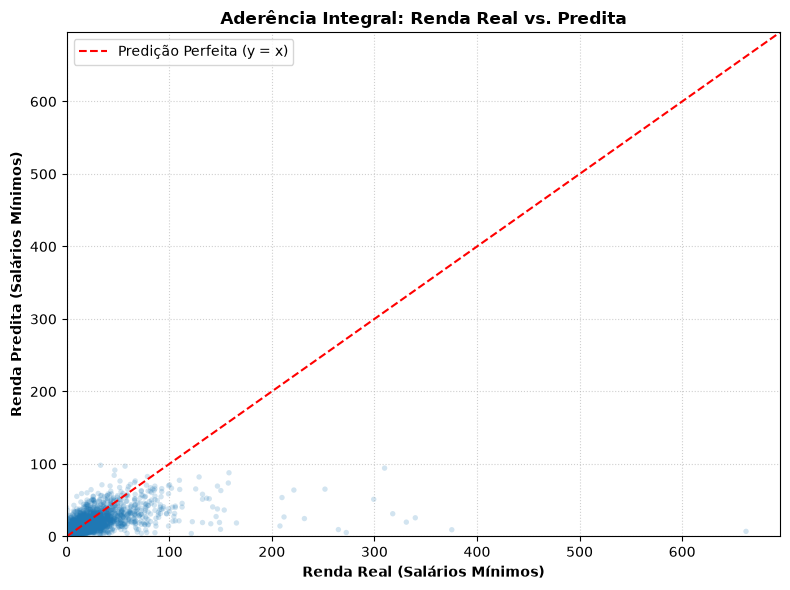

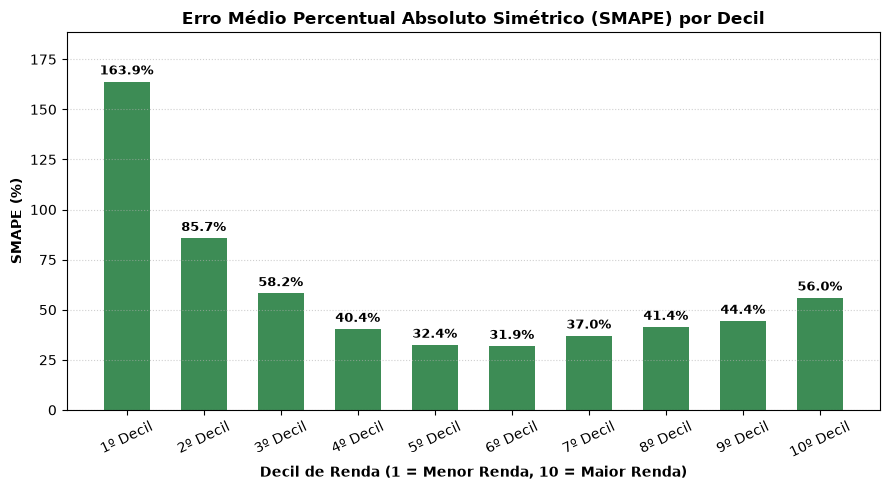


Diagnóstico Gráfico - Teste Brasília Completo (Modelo Treinado sem 1º Decil):

📊 2. TABELA DIAGNÓSTICA POR DECIL PONDERADO:
    Decil    N  Minimo  Mediana  Media  Maximo  Desvio_Padrao  Vies_Medio   SMAPE
 1º Decil 5495    0.00     1.00  0.745    1.42          0.508       2.769 124.549
 2º Decil 5465    1.42     1.99  1.924    2.32          0.240       1.774  54.380
 3º Decil 5416    2.32     2.97  2.896    3.32          0.302       1.480  37.912
 4º Decil 5378    3.32     3.97  4.035    4.65          0.383       0.989  34.056
 5º Decil 5457    4.65     5.60  5.624    6.62          0.548       0.607  36.043
 6º Decil 5357    6.62     7.85  7.778    9.27          0.783      -0.058  39.941
 7º Decil 5385    9.27    11.13 11.208   13.25          1.249      -1.078  43.898
 8º Decil 5340   13.25    16.56 16.876   20.87          2.204      -3.206  47.101
 9º Decil 5340   20.87    26.78 27.662   36.42          4.386      -8.273  53.241
10º Decil 5254   36.42    54.30 68.899 3703.64         

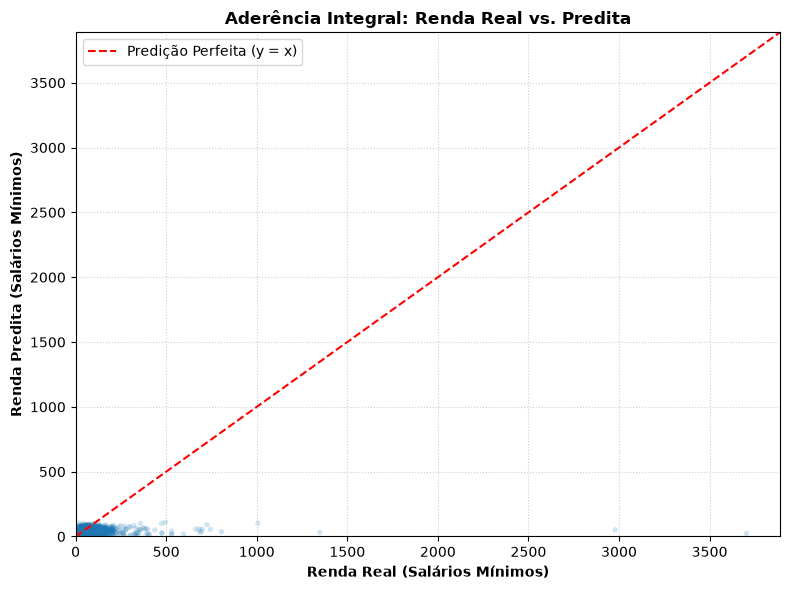

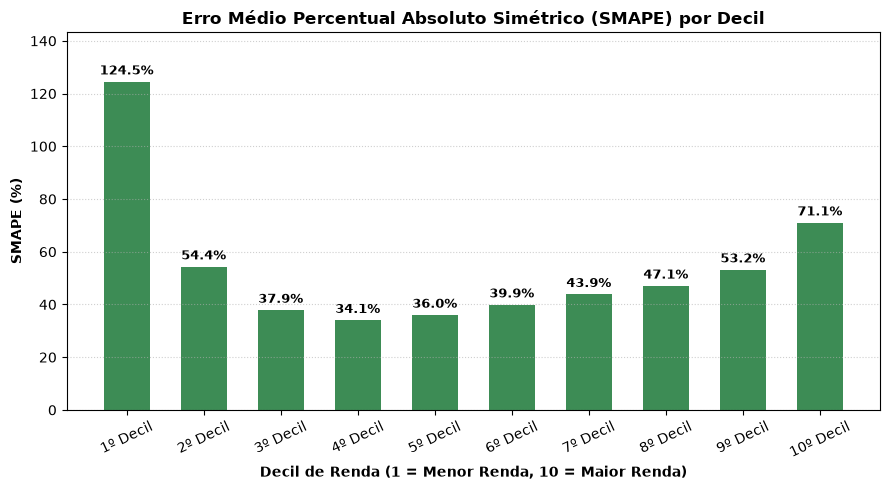

15708

In [21]:
# ==============================================================================
# EXPERIMENTO: TREINAMENTO SEM O 1º DECIL EM SALVADOR E TESTE COMPLETO EM SALVADOR E BRASÍLIA
# ==============================================================================
# 1. Determinação do ponto de corte do 1º decil (Percentil 10%) no conjunto de Treino+Validação de Salvador
corte_decil_1 = float(np.quantile(train_val_y, 0.10))
print(f"Valor de corte do 1º Decil (Percentil 10%) em Salvador: {corte_decil_1:.4f} SM")
# 2. Máscara booleana para exclusão estrita do 1º decil na base de treinamento
mask_sem_d1 = train_val_y > corte_decil_1
train_val_x_sem_d1 = train_val_x[mask_sem_d1].reset_index(drop=True)
train_val_y_sem_d1 = train_val_y[mask_sem_d1].astype(np.float32)
train_val_w_sem_d1 = train_val_w[mask_sem_d1].astype(np.float32)
print(f"Total de domicílios Treino+Validação (Original):  {len(train_val_y)}")
print(f"Total de domicílios Treino+Validação (Sem 1º Decil): {len(train_val_y_sem_d1)} (Removidos: {np.sum(~mask_sem_d1)})")
# 3. Criação da DMatrix de treino sem o primeiro decil
dtrain_val_sem_d1 = xgb.DMatrix(
    data=train_val_x_sem_d1,
    label=train_val_y_sem_d1,
    weight=train_val_w_sem_d1,
)
del train_val_x_sem_d1, train_val_x
gc.collect()
# 4. Parâmetros do modelo (alinhados aos hiperparâmetros de referência)
params_exp = {
    "objective": obj_opt if 'obj_opt' in locals() else "reg:pseudohubererror",
    "learning_rate": float(melhor_p["eta"]) if 'melhor_p' in locals() else 0.01,
    "max_depth": int(round(melhor_p["max_depth"])) if 'melhor_p' in locals() else 6,
    "subsample": float(melhor_p["subsample"]) if 'melhor_p' in locals() else 0.5,
    "colsample_bytree": float(melhor_p["colsample_bytree"]) if 'melhor_p' in locals() else 1.0,
    "alpha": float(melhor_p["alpha"]) if 'melhor_p' in locals() else 1.0,
    "lambda": float(melhor_p["lambda_reg"]) if 'melhor_p' in locals() else 1.0,
    "tree_method": "hist",
    "nthread": 4,
    "random_state": 42,
}
if params_exp["objective"] == "reg:pseudohubererror":
    params_exp["huber_slope"] = float(melhor_p["huber_slope"]) if 'melhor_p' in locals() else 1.0
elif params_exp["objective"] == "reg:tweedie":
    params_exp["tweedie_variance_power"] = 1.5
nrounds_exp = nrounds_opt if 'nrounds_opt' in locals() else 1000
print("\nTreinando modelo XGBoost com a base de Salvador SEM o 1º Decil...")
modelo_xgb_sem_d1 = xgb.train(
    params=params_exp,
    dtrain=dtrain_val_sem_d1,
    num_boost_round=nrounds_exp,
    evals=[(dtrain_val_sem_d1, "train_sem_d1")],
    custom_metric=eval_smape_censo,
    verbose_eval=100,
    maximize=False,
)
# ==============================================================================
# 5. PREDIÇÕES (TRUNCADAS EM ZERO)
# ==============================================================================
# Treino ajustado sem D1
pred_train_sem_d1 = np.maximum(0.0, modelo_xgb_sem_d1.predict(dtrain_val_sem_d1)).ravel()
# Teste Salvador COMPLETO (contém 100% dos dados, incluindo o 1º Decil)
pred_test_ba_sem_d1 = np.maximum(0.0, modelo_xgb_sem_d1.predict(dtest)).ravel()
# Teste Brasília (DF) COMPLETO (SEM REMOVER O 1º DECIL)
pred_test_bsb_sem_d1 = np.maximum(0.0, modelo_xgb_sem_d1.predict(dbsb)).ravel()
# ==============================================================================
# 6. RELATÓRIOS PADRONIZADOS VIA gerar_relatorio()
# ==============================================================================
print("\n" + "=" * 65)
print(" RELATÓRIO 1: SALVADOR (TREINO SEM 1º DECIL vs. TESTE SALVADOR COMPLETO)")
print("=" * 65)
tabela_ba_sem_d1 = gerar_relatorio(
    pred_train=pred_train_sem_d1,
    pred_test=pred_test_ba_sem_d1,
    y_treino=train_val_y_sem_d1,
    y_teste=test_y,
    w_treino=train_val_w_sem_d1,
    w_teste=test_w,
)
print("\n" + "=" * 65)
print(" RELATÓRIO 2: BRASÍLIA - DF (TESTE EXTERNO COMPLETO SEM REMOÇÃO DE DECIL)")
print("=" * 65)
tabela_bsb_sem_d1 = gerar_relatorio(
    pred_test=pred_test_bsb_sem_d1,
    y_teste=y_bsb,
    w_teste=w_bsb,
)
tabela_bsb_sem_d1["Base"] = "Teste Externo (Brasília - Completo)"
# ==============================================================================
# 7. RELATÓRIOS COMPARATIVOS PADRONIZADOS (via gerar_relatorio)
# ==============================================================================
# Comparativo Direto em Salvador (Original vs. Sem 1º Decil)
print("\n" + "=" * 65)
print(" RELATÓRIO COMPARATIVO: TESTE SALVADOR COMPLETO (ORIGINAL vs. SEM 1º DECIL)")
print("=" * 65)
relatorio_comp_ba = gerar_relatorio(
    pred_train=pred_test_opt,
    pred_test=pred_test_ba_sem_d1,
    y_treino=test_y,
    y_teste=test_y,
    w_treino=test_w,
    w_teste=test_w,
)
relatorio_comp_ba["Base"] = ["Original (Com 1º Decil)", "Sem 1º Decil no Treino"]
relatorio_comp_ba["Cenário"] = "Salvador (Teste Completo)"
# Comparativo Direto em Brasília (Original vs. Sem 1º Decil)
print("\n" + "=" * 65)
print(" RELATÓRIO COMPARATIVO: TESTE BRASÍLIA COMPLETO (ORIGINAL vs. SEM 1º DECIL)")
print("=" * 65)
relatorio_comp_bsb = gerar_relatorio(
    pred_train=pred_bsb,
    pred_test=pred_test_bsb_sem_d1,
    y_treino=y_bsb,
    y_teste=y_bsb,
    w_treino=w_bsb,
    w_teste=w_bsb,
)
relatorio_comp_bsb["Base"] = ["Original (Com 1º Decil)", "Sem 1º Decil no Treino"]
relatorio_comp_bsb["Cenário"] = "Brasília - DF (Teste Completo)"
# Tabela Consolidada Geral derivada diretamente dos relatórios oficiais
tabela_comparativa = pd.concat([relatorio_comp_ba, relatorio_comp_bsb], ignore_index=True)
tabela_comparativa = tabela_comparativa[["Cenário", "Base", "RMSE", "MAE", "R2", "SMAPE"]]
tabela_comparativa.rename(columns={"Base": "Modelo"}, inplace=True)
print("\n" + "=" * 85)
print(" RESUMO COMPARATIVO GERAL: MODELO ORIGINAL vs. MODELO TREINADO SEM O 1º DECIL")
print("=" * 85)
print(tabela_comparativa.to_string(index=False))
print("=" * 85)
# ==============================================================================
# 8. DIAGNÓSTICOS GRÁFICOS POR DECIL DE RENDA
# ==============================================================================
print("\nDiagnóstico Gráfico - Teste Salvador Completo (Modelo Treinado sem 1º Decil):")
plot_validation(
    plot_y=test_y,
    plot_pred=pred_test_ba_sem_d1,
    plot_w=test_w,
    mostrar_metricas_globais=False,
)
print("\nDiagnóstico Gráfico - Teste Brasília Completo (Modelo Treinado sem 1º Decil):")
plot_validation(
    plot_y=y_bsb,
    plot_pred=pred_test_bsb_sem_d1,
    plot_w=w_bsb,
    mostrar_metricas_globais=False,
)
plt.close("all")
gc.collect()
